# 🚀 Đánh Giá Benchmark Toàn Diện Method 8 Trên 4,999 Trang DocLayNet

**Mô hình:** `SpatialSidecarRTDetrMethod8` (RT-DETRv2 Backbone + Spatial Layout Sidecar CNN 22 kênh + Zero-Gated Multi-Scale Feature Fusion)  
**Trọng số:** `methods/method8/weights/method8_best.pth`  
**Tập dữ liệu đánh giá:** 4,999 trang tài liệu (`datasets/doclaynet_test/processed/annotations/test.json` — 66,531 ground-truth boxes thuộc 11 lớp cấu trúc DocLayNet)

---

### 📌 Tóm tắt các nhóm chỉ số đánh giá trong Notebook:
1. **Strict & Localization-only (Loose) Precision / Recall / F1** (Micro, Macro và chi tiết từng lớp tại `IoU >= 0.50`).
2. **Phân tích lỗi 2 giai đoạn (`print_error_analysis`)**:
   - **Giai đoạn 1 (Detection)** & **Giai đoạn 2 (Classification)** & **End-to-End F1**.
   - **Phân tích lỗi Tách / Gộp box (Split & Merge rates)** và các tổ hợp lớp hay bị gộp.
   - **Bảng A (Số phận GT theo lớp)**, **Bảng B (Nguồn gốc Pred theo lớp)** và **Bảng C (Confusion Matrix)**.
   - **Thang đo tham chiếu độ khít biên (`print_localization_reference` & `jitter_ceiling`)** và **Bảng tóm tắt đa ngưỡng IoU (`0.50`, `0.75`, `0.95`)**.
3. **Chuẩn quốc tế COCO mAP**: `mAP@[.50:.95]`, `mAP@50`, `mAP@75`, `mAP small/medium/large`, `AR@1/10/100` và `AP / AP50` từng lớp.
4. **Trực quan hóa (Visualization)**: Biểu đồ `metrics_chart.png` và **10 ảnh đối chiếu trực tiếp Ground Truth vs. Method 8 Prediction**.

In [1]:
from pathlib import Path
import subprocess
import sys
import torch

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

METHOD = "method8"
DATASET = "doclaynet_test"
SPLIT = "test"
PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
REPORTS_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
FIGURES_DIR = ROOT / "visualization" / "figures" / f"{METHOD}_{DATASET}"

device = f"cuda ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else "cpu"
num_preds = len(list(PREDICTIONS_DIR.glob("*.json")))
print(f"Project Root   : {ROOT}")
print(f"Method         : {METHOD} (SpatialSidecarRTDetrMethod8)")
print(f"Benchmark Split: {DATASET}/{SPLIT} ({num_preds:,} prediction files ready)")
print(f"Device         : {device}")

Project Root   : d:\Semester_261\DoAnChuyenNganh\DO-AN-261
Method         : method8 (SpatialSidecarRTDetrMethod8)
Benchmark Split: doclaynet_test/test (4,999 prediction files ready)
Device         : cuda (NVIDIA GeForce RTX 4070 Laptop GPU)


## 1. Đánh Giá Toàn Diện: Strict/Loose F1, COCO mAP@[.50:.95] / mAP@50 / mAP@75 & Phân Tích Lỗi 2 Giai Đoạn (`print_error_analysis`)

Thực thi `scripts/evaluate_predictions.py` trên toàn bộ **4,999 trang** (`66,531` GT boxes) với đầy đủ các hàm phân tích lỗi mới trong `src/common/metrics.py` và hiển thị biểu đồ `metrics_chart.png`.

TAP DANH GIA: TEST (doclaynet_test) - bao cao ket qua cuoi cung
[note] Tap TEST chi de bao cao cuoi cung; chon nguong / cach map nhan tren tap valid.
Evaluation: method8 on doclaynet_test/test | 4999 images | GT=66,531 boxes | Predictions=79,657 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.786  Recall=0.941  F1=0.856  TP=62598 FP=17059 FN=3933  mean IoU=0.928
Macro (mean across 11 ground-truth classes): Precision=0.761  Recall=0.931  F1=0.837
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                 29940   35160  28334   6826   1606    0.806    0.946    0.870
List-item            10522   12557   9853   2704    669    0.785    0.936    0.854
Section-header        8550   10112   7954   2158    596    0.787    0.930    0.852
Page-footer           3994    4759   3798    961    196    0.798    0.951    0.868
Picture               3534    4767   3232   1535    302    0.678    0.915    0.779
Page-header           336

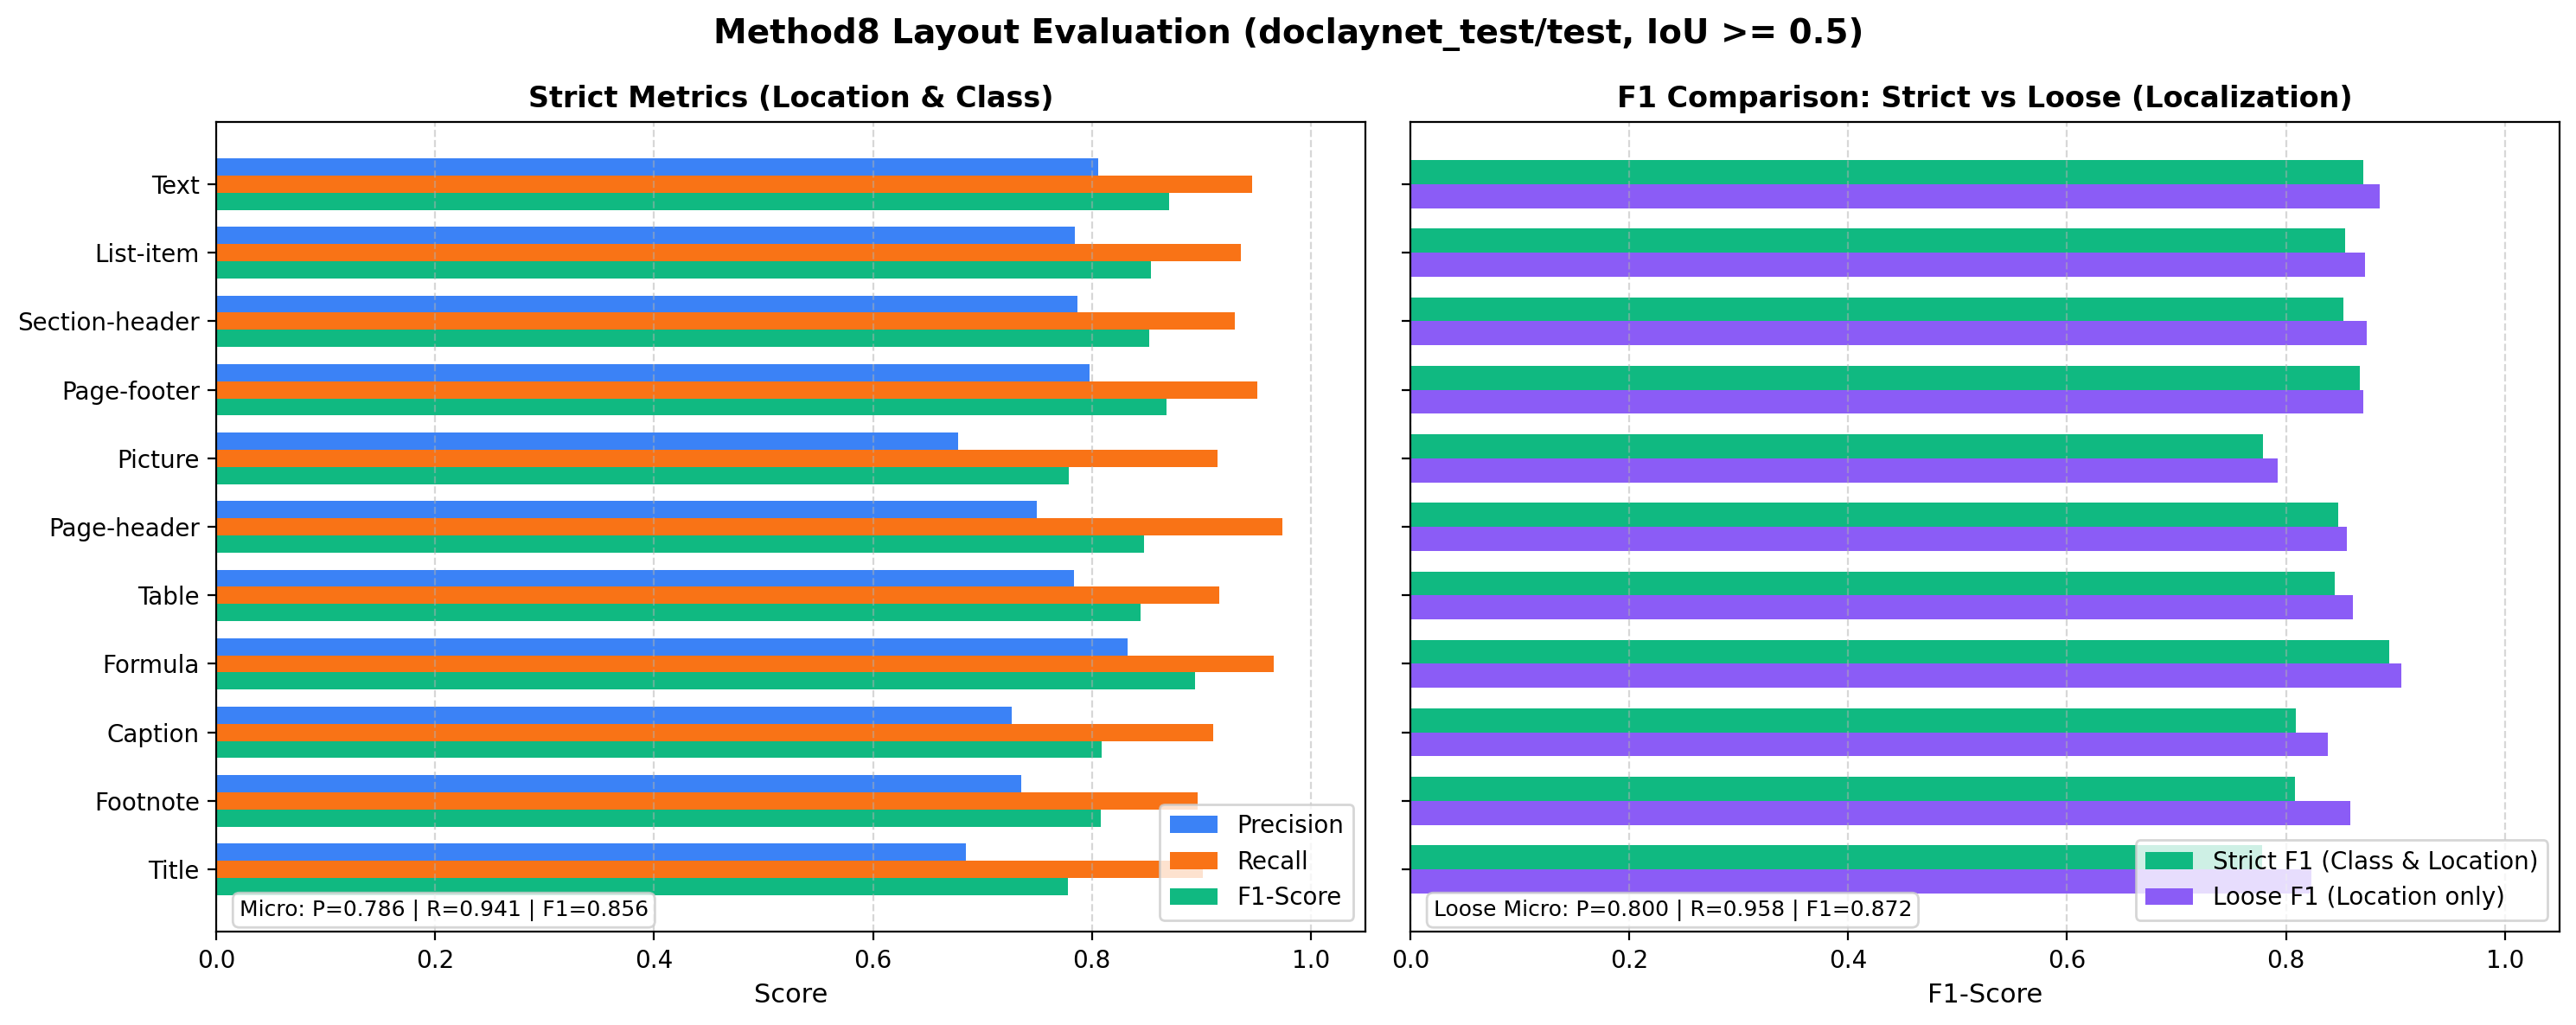

In [2]:
from IPython.display import Image as IPImage, display

chart_path = REPORTS_DIR / "metrics_chart.png"
cmd = [
    sys.executable,
    str(ROOT / "scripts" / "evaluate_predictions.py"),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", "0.5",
    "--loose",
    "--plot", str(chart_path),
]
res = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
print(res.stdout)
if chart_path.exists():
    display(IPImage(filename=str(chart_path)))

### 💡 Nhận xét kết quả Benchmark của Method 8 trên 4,999 trang:
- **COCO mAP đạt kỷ lục mới trong các mô hình thử nghiệm:**
  - **`mAP@[.50:.95] = 0.771 (77.1%)`**, **`mAP@50 = 0.900 (90.0%)`**, **`mAP@75 = 0.826 (82.6%)`**, vượt xa baseline **Docling** (`0.606` / `0.753` / `0.656`) và vượt qua cả mô hình đa phương thức nặng **M2Doc** (`0.766` / `0.869`).
- **Độ phủ (Recall) và khả năng khắc phục điểm mù lớp `Title`:**
  - **Strict Recall đạt `94.1%`** (`62,598 / 66,531` GT boxes được định vị và phân loại đúng) và **Loose Recall đạt `95.8%`**.
  - Đặc biệt, lớp **`Title`** vốn bị Docling bỏ sót hoàn toàn (`0.0%` F1 và `0.0%` AP) đã được Method 8 khôi phục mạnh mẽ lên **`Strict F1 = 0.778`** (`Recall = 90.1%`, `AP@[.50:.95] = 0.795`, `AP50 = 0.876`) nhờ bản đồ nhiệt ngữ cảnh 22 kênh từ Sidecar CNN.
- **Phân tích lỗi 2 giai đoạn (`print_error_analysis`):**
  - **Độ chính xác phân loại Giai đoạn 2 (`Cls-Accuracy`) đạt `97.93%`**.
  - **Tỉ lệ bỏ sót GT thấp nhất tuyệt đối:** Chỉ bỏ sót **`117 / 66,531` box (`0.18%`)**, giảm 7.5 lần so với Docling (`878` box).
  - **Tỉ lệ gộp box (`Merge rate`) thấp nhất:** Chỉ **`3.94%`** (so với `5.93%` của Docling và `4.32%` của M2Doc).
  - **Độ khít biên định vị (`print_localization_reference`) xuất sắc nhất:** Sai lệch trung bình 4 cạnh chỉ **`0.61px`** (`68.3%` số box lệch `<= 1px`, `88.0%` lệch `<= 2px`), tương đương độ lệch ngẫu nhiên chỉ **`±1.0px`**, đạt **`263/4,999` trang hoàn hảo tuyệt đối ở ngưỡng khắt khe `IoU >= 0.95` (`5.26%`)**.

## 2. Trực Quan Hóa 10 Trang Tài Liệu Mẫu (Ground Truth vs. Method 8 Prediction)

Sử dụng `visualization/scripts/visualize_predictions.py` để vẽ đối chiếu trực tiếp **Ground Truth (bên trái)** và **Dự đoán của Method 8 (bên phải)** trên 10 trang tài liệu thuộc tập benchmark.

=== Sample Page 1 (1.png) ===
=== Sample Page 2 (2.png) ===
=== Sample Page 3 (3.png) ===
=== Sample Page 4 (4.png) ===
=== Sample Page 5 (5.png) ===
=== Sample Page 6 (6.png) ===
=== Sample Page 7 (7.png) ===
=== Sample Page 8 (8.png) ===
=== Sample Page 9 (9.png) ===
=== Sample Page 10 (10.png) ===


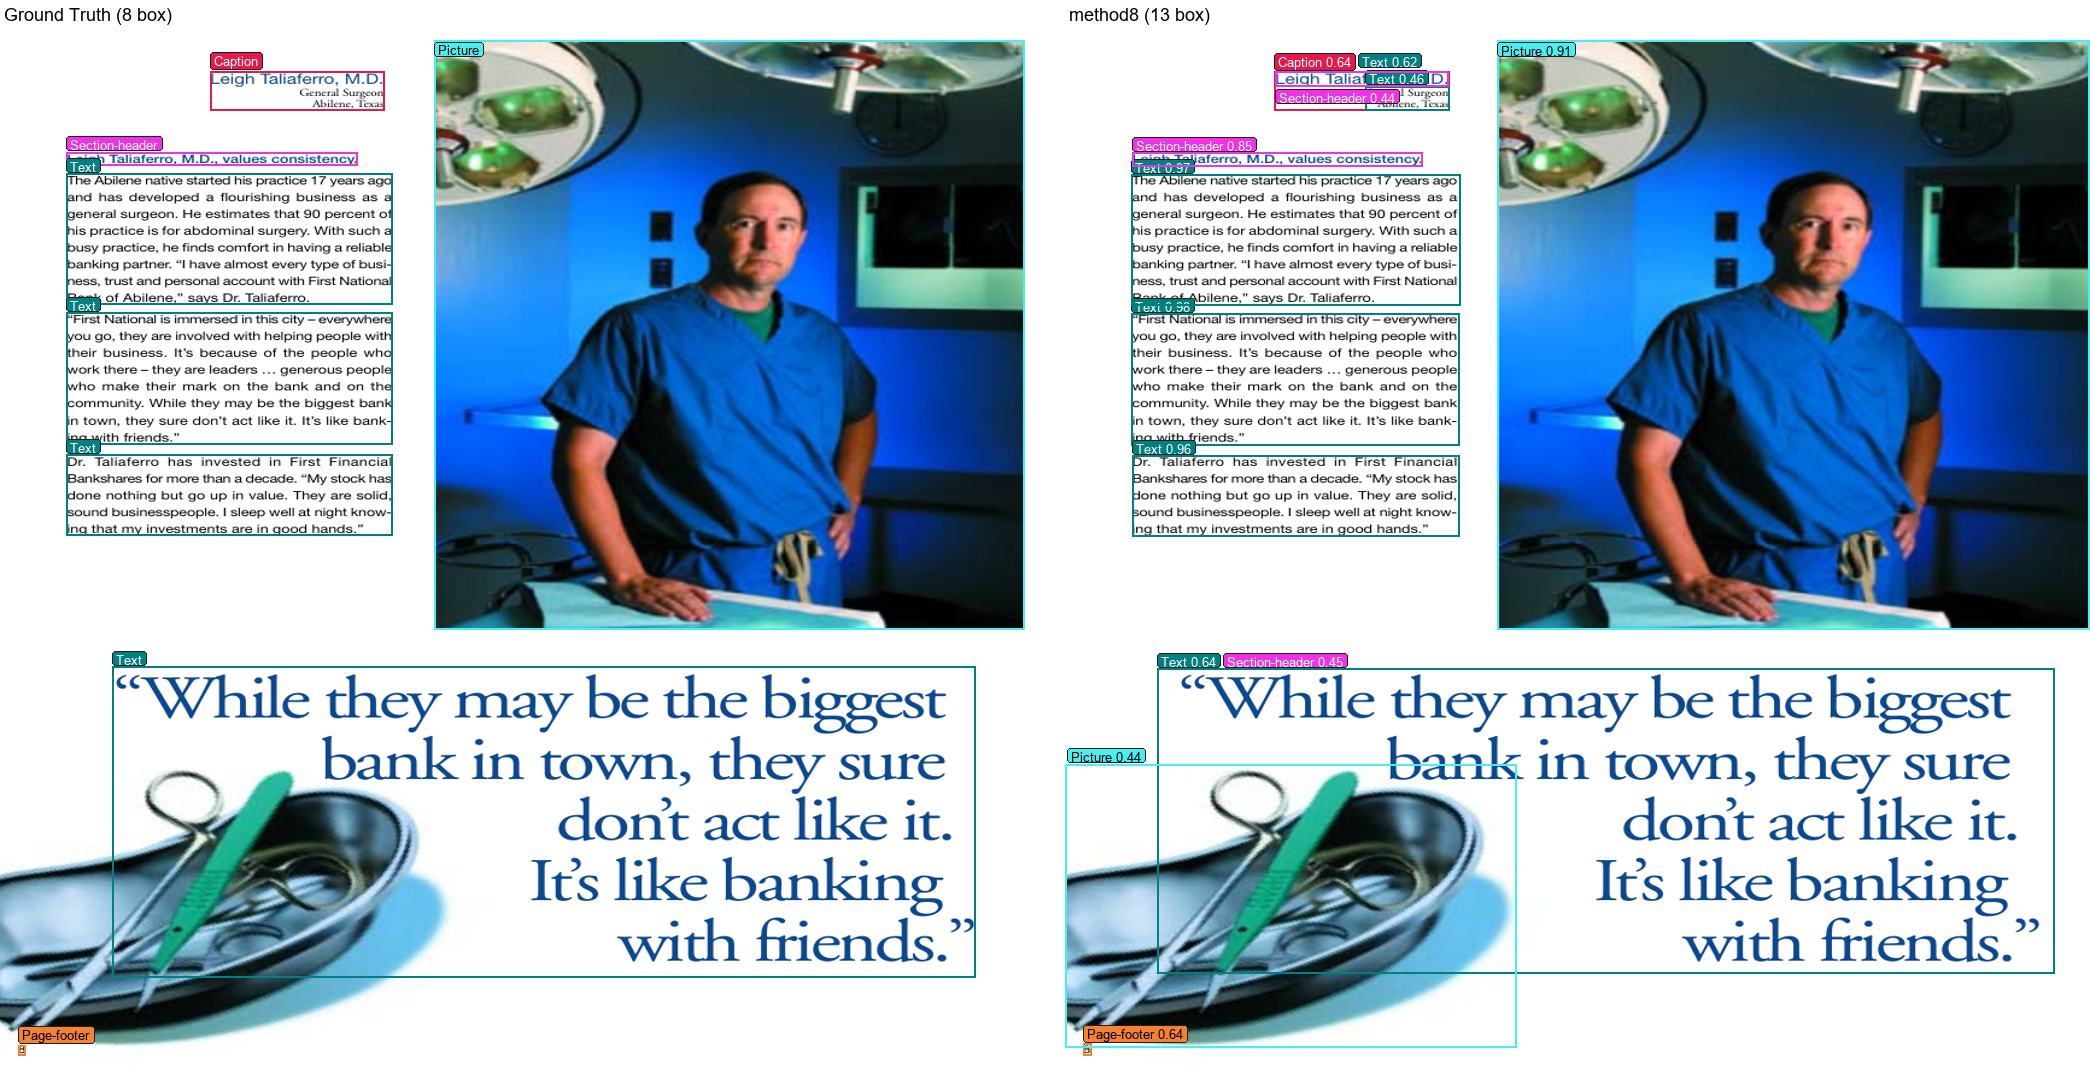

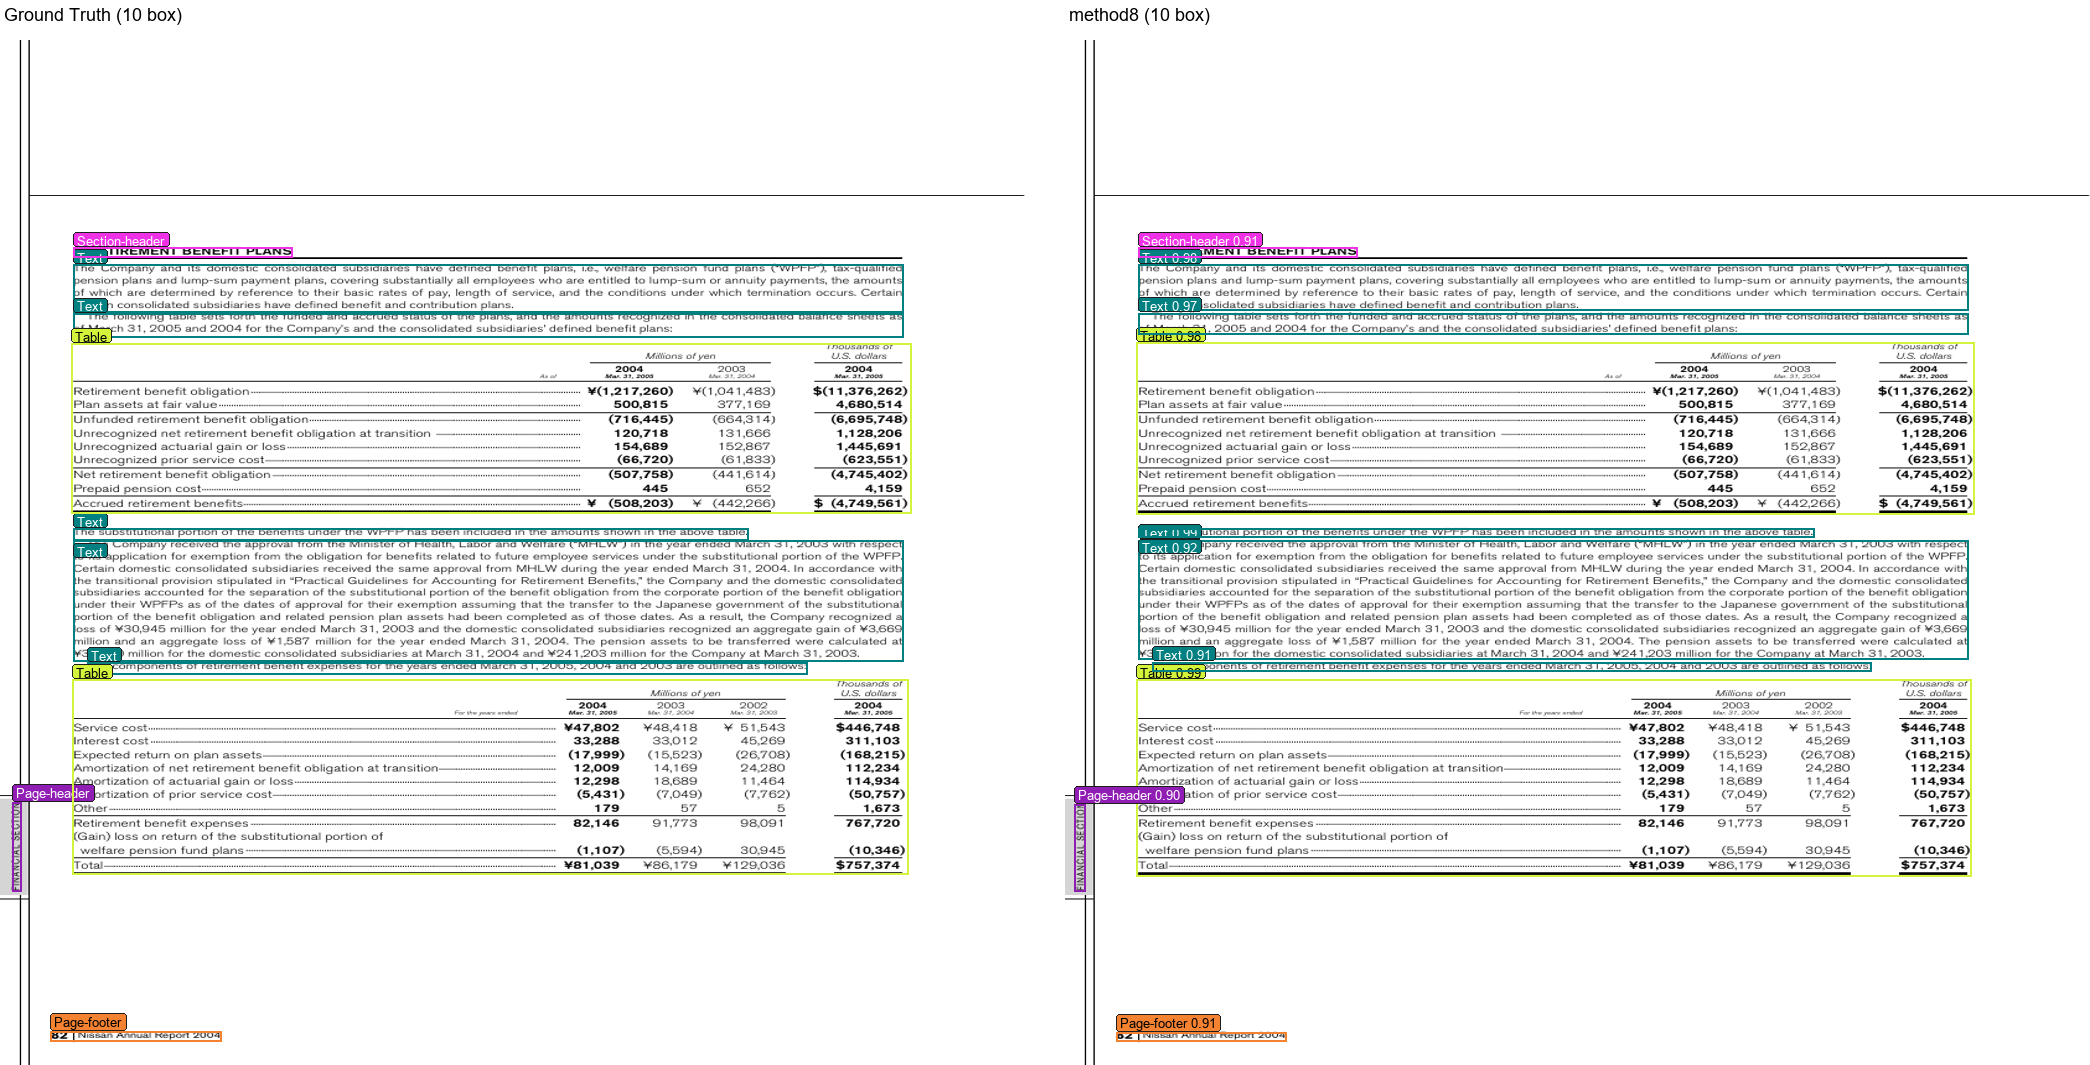

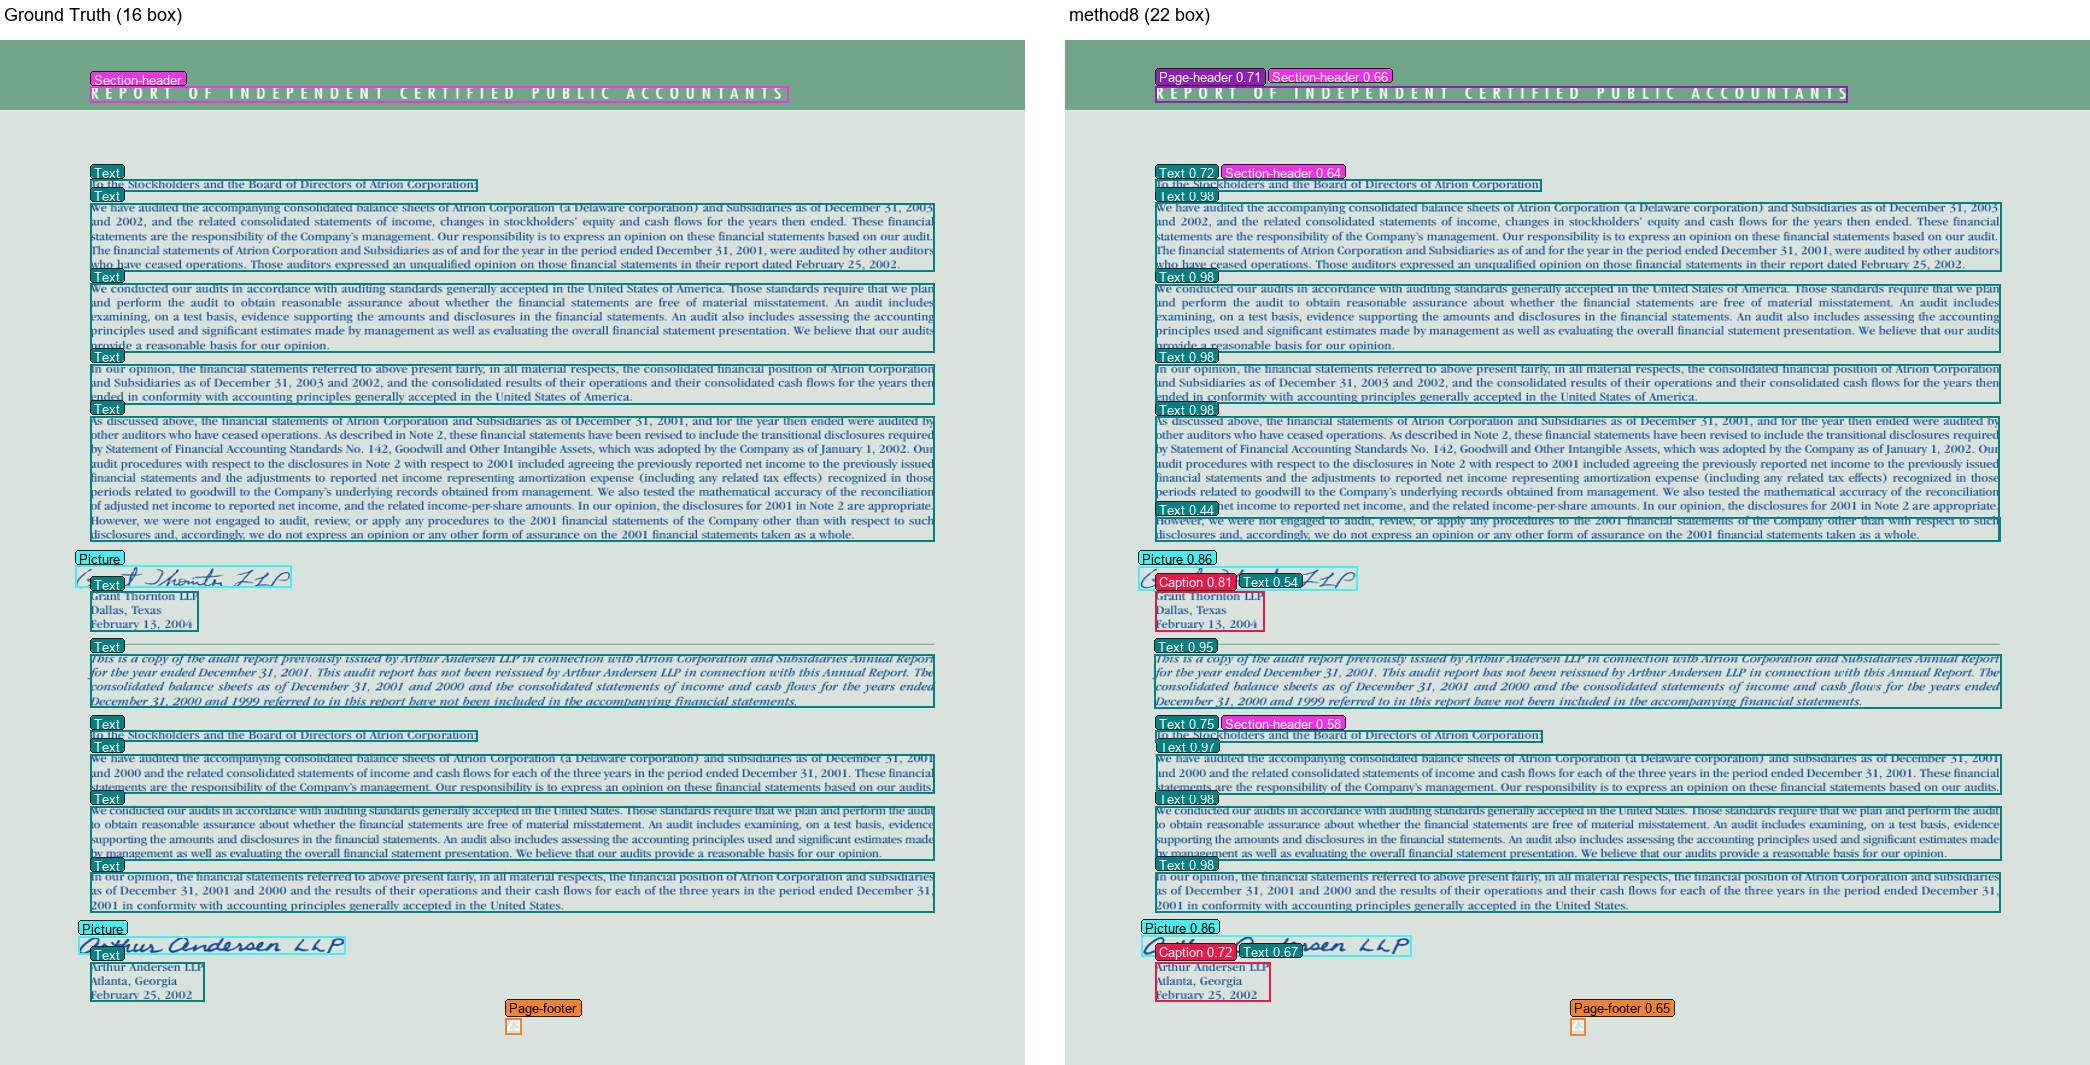

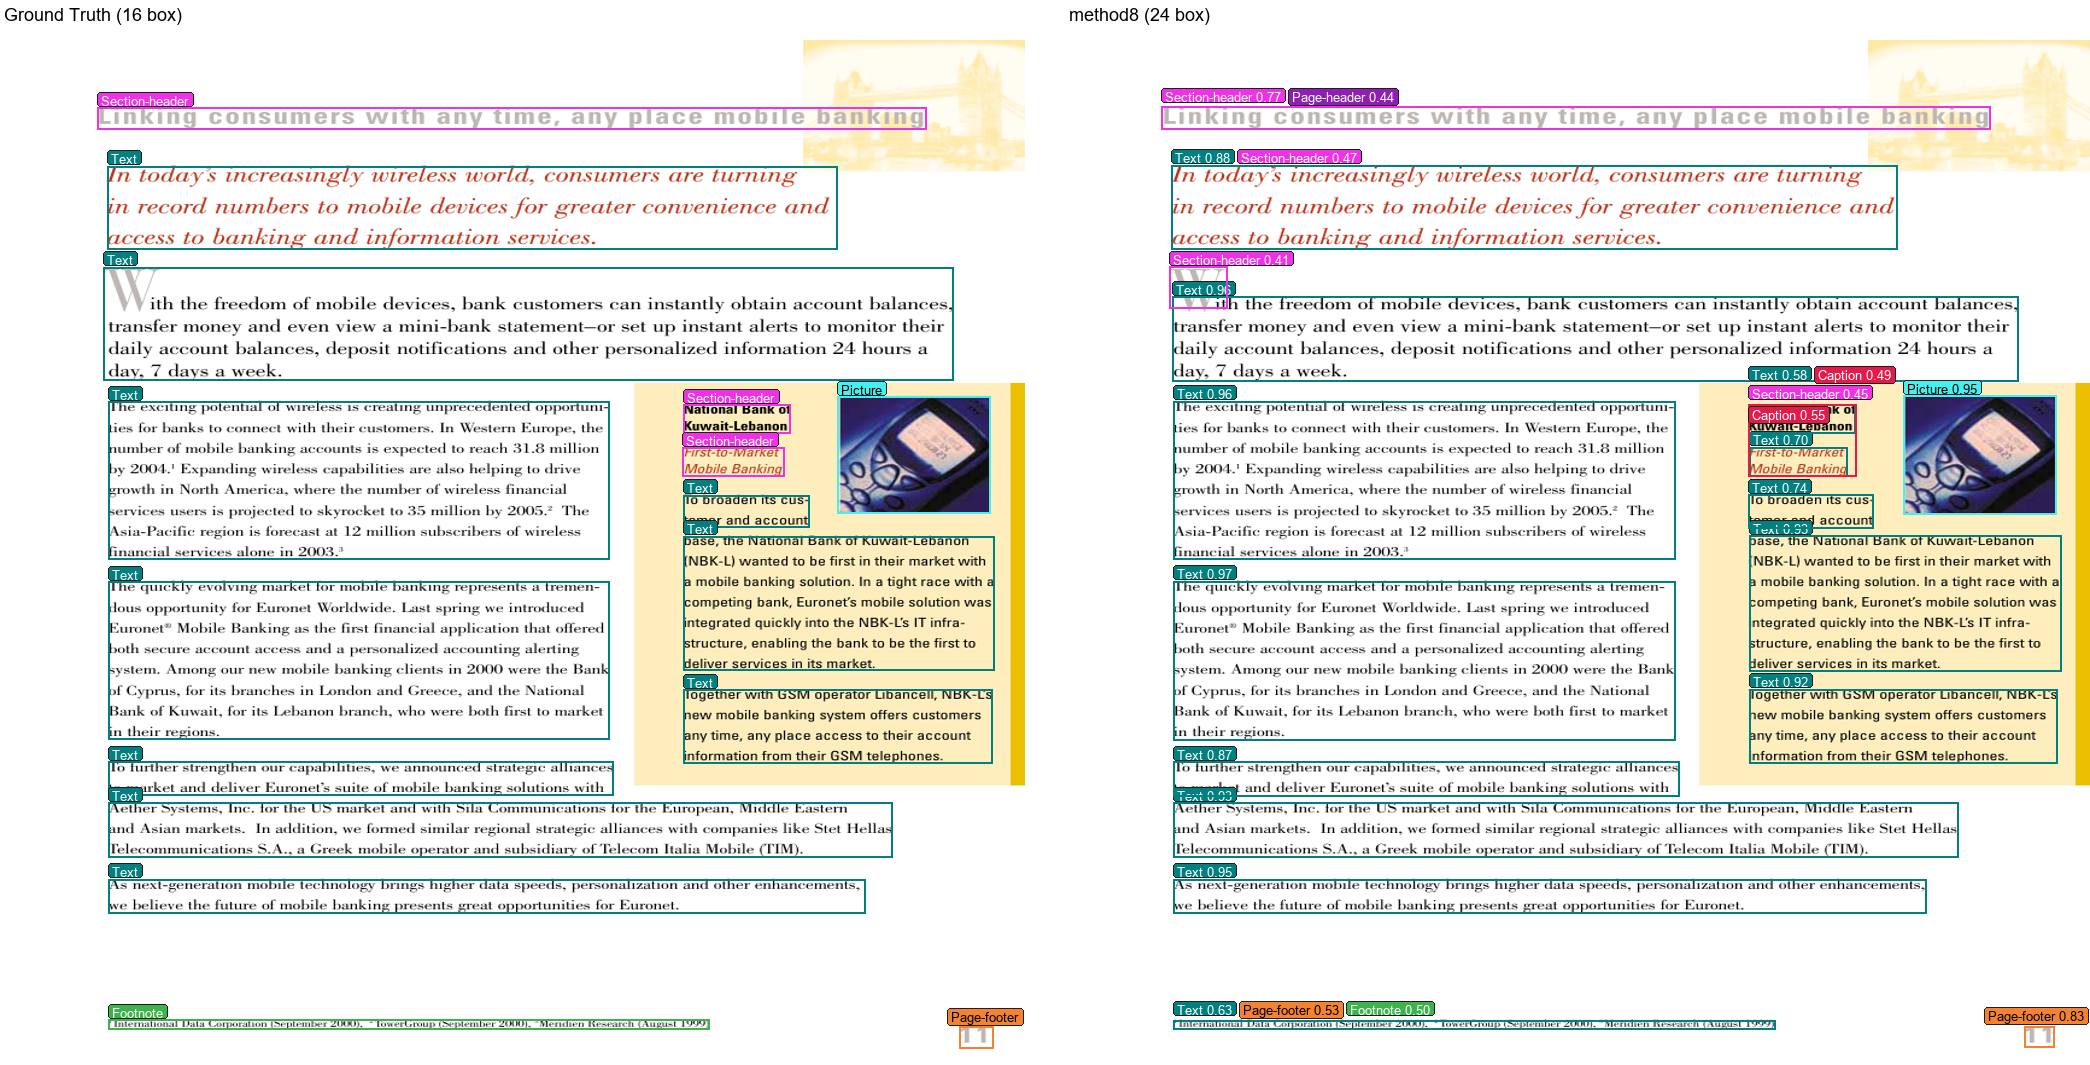

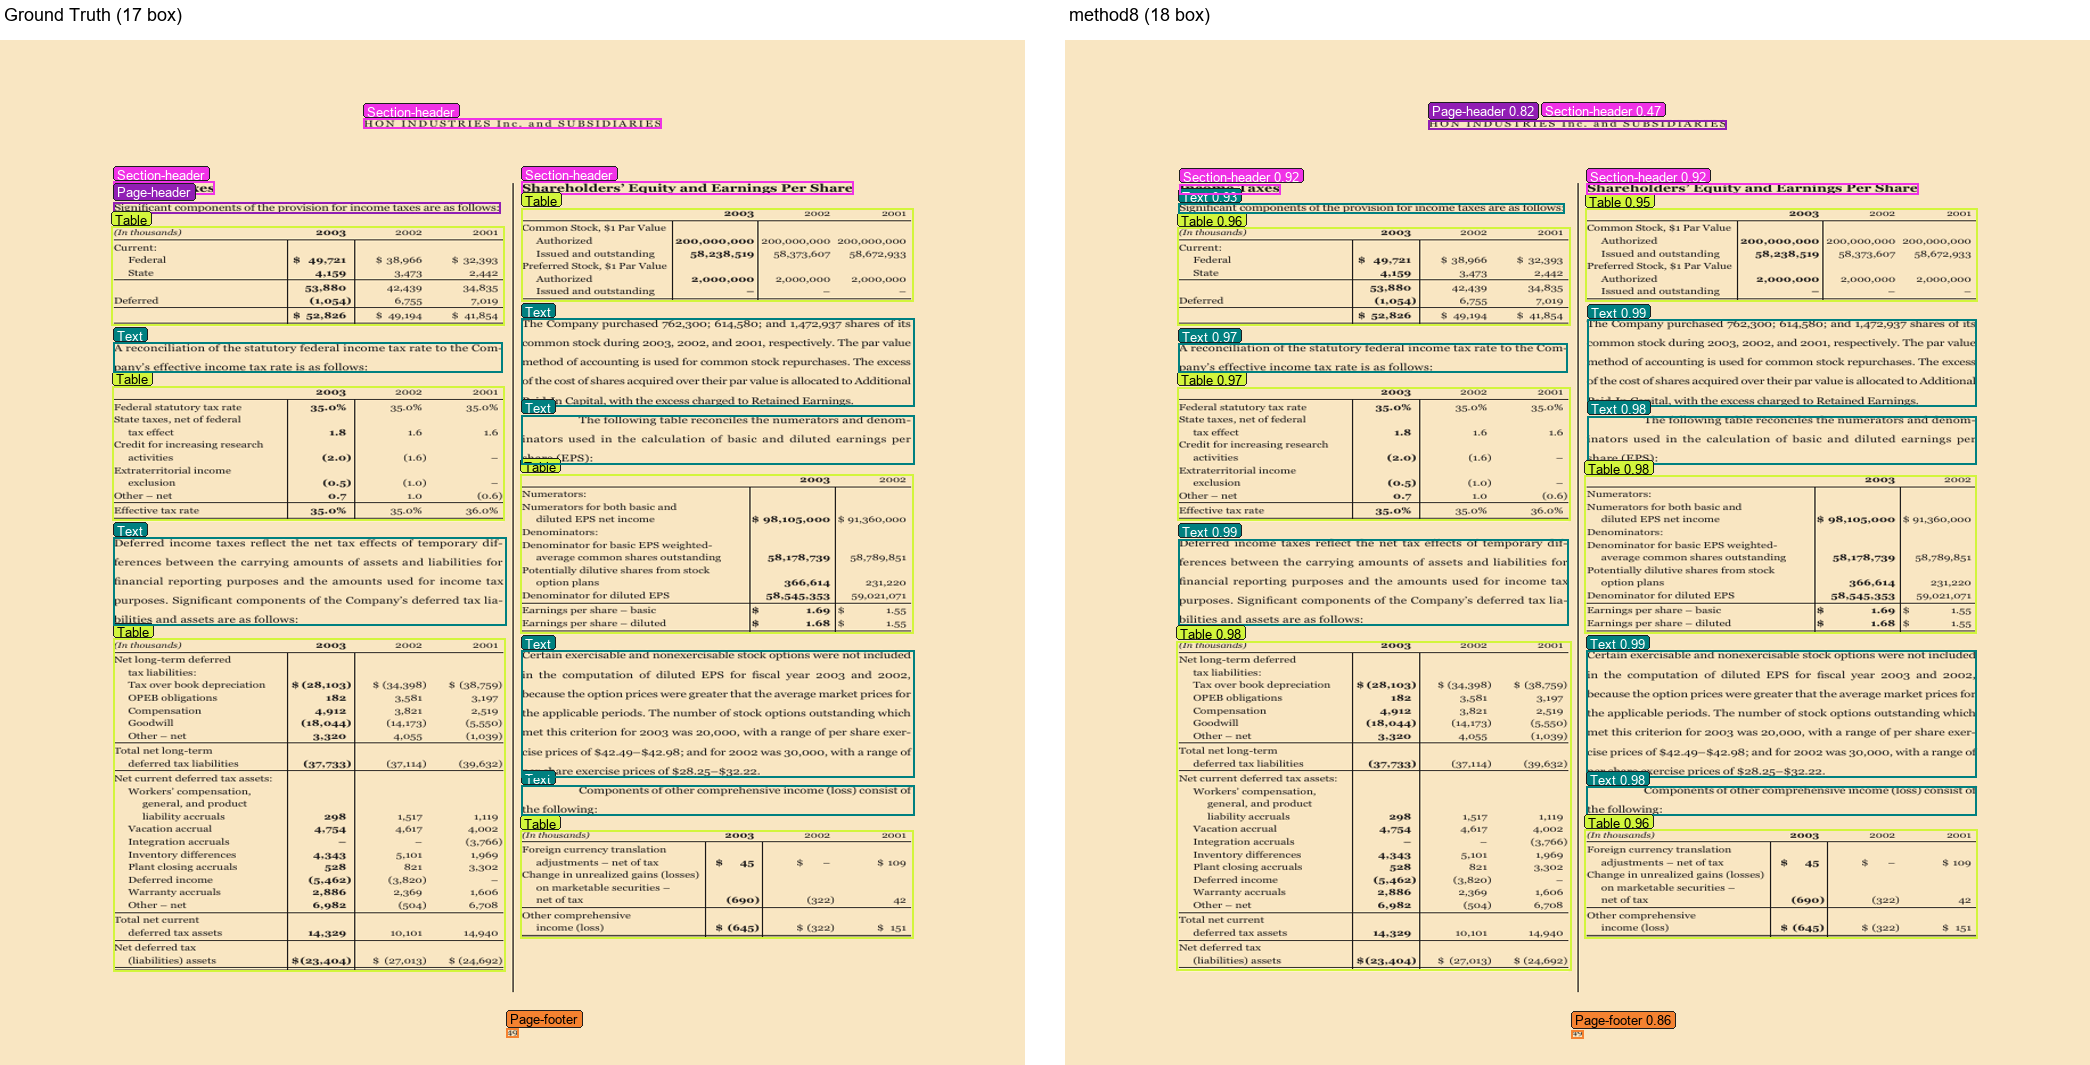

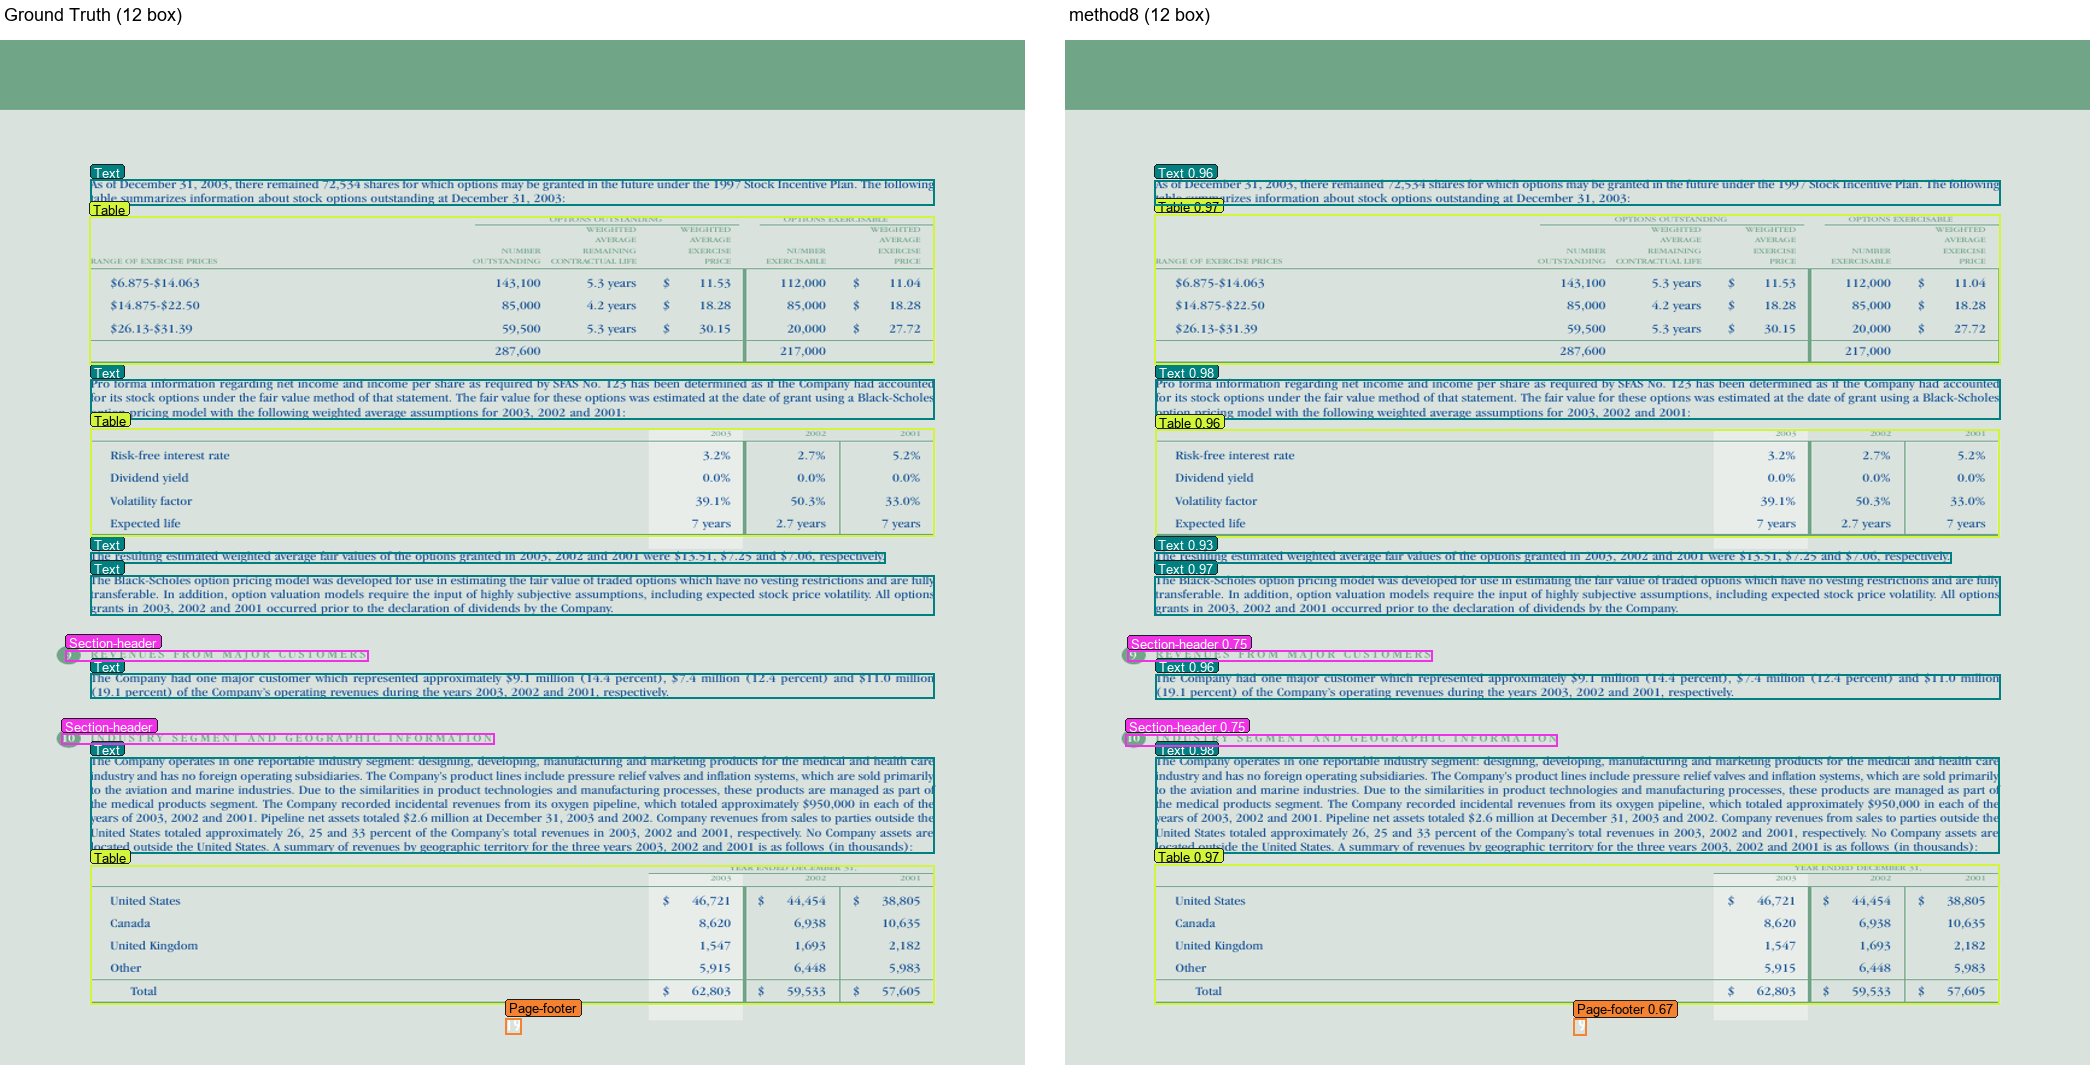

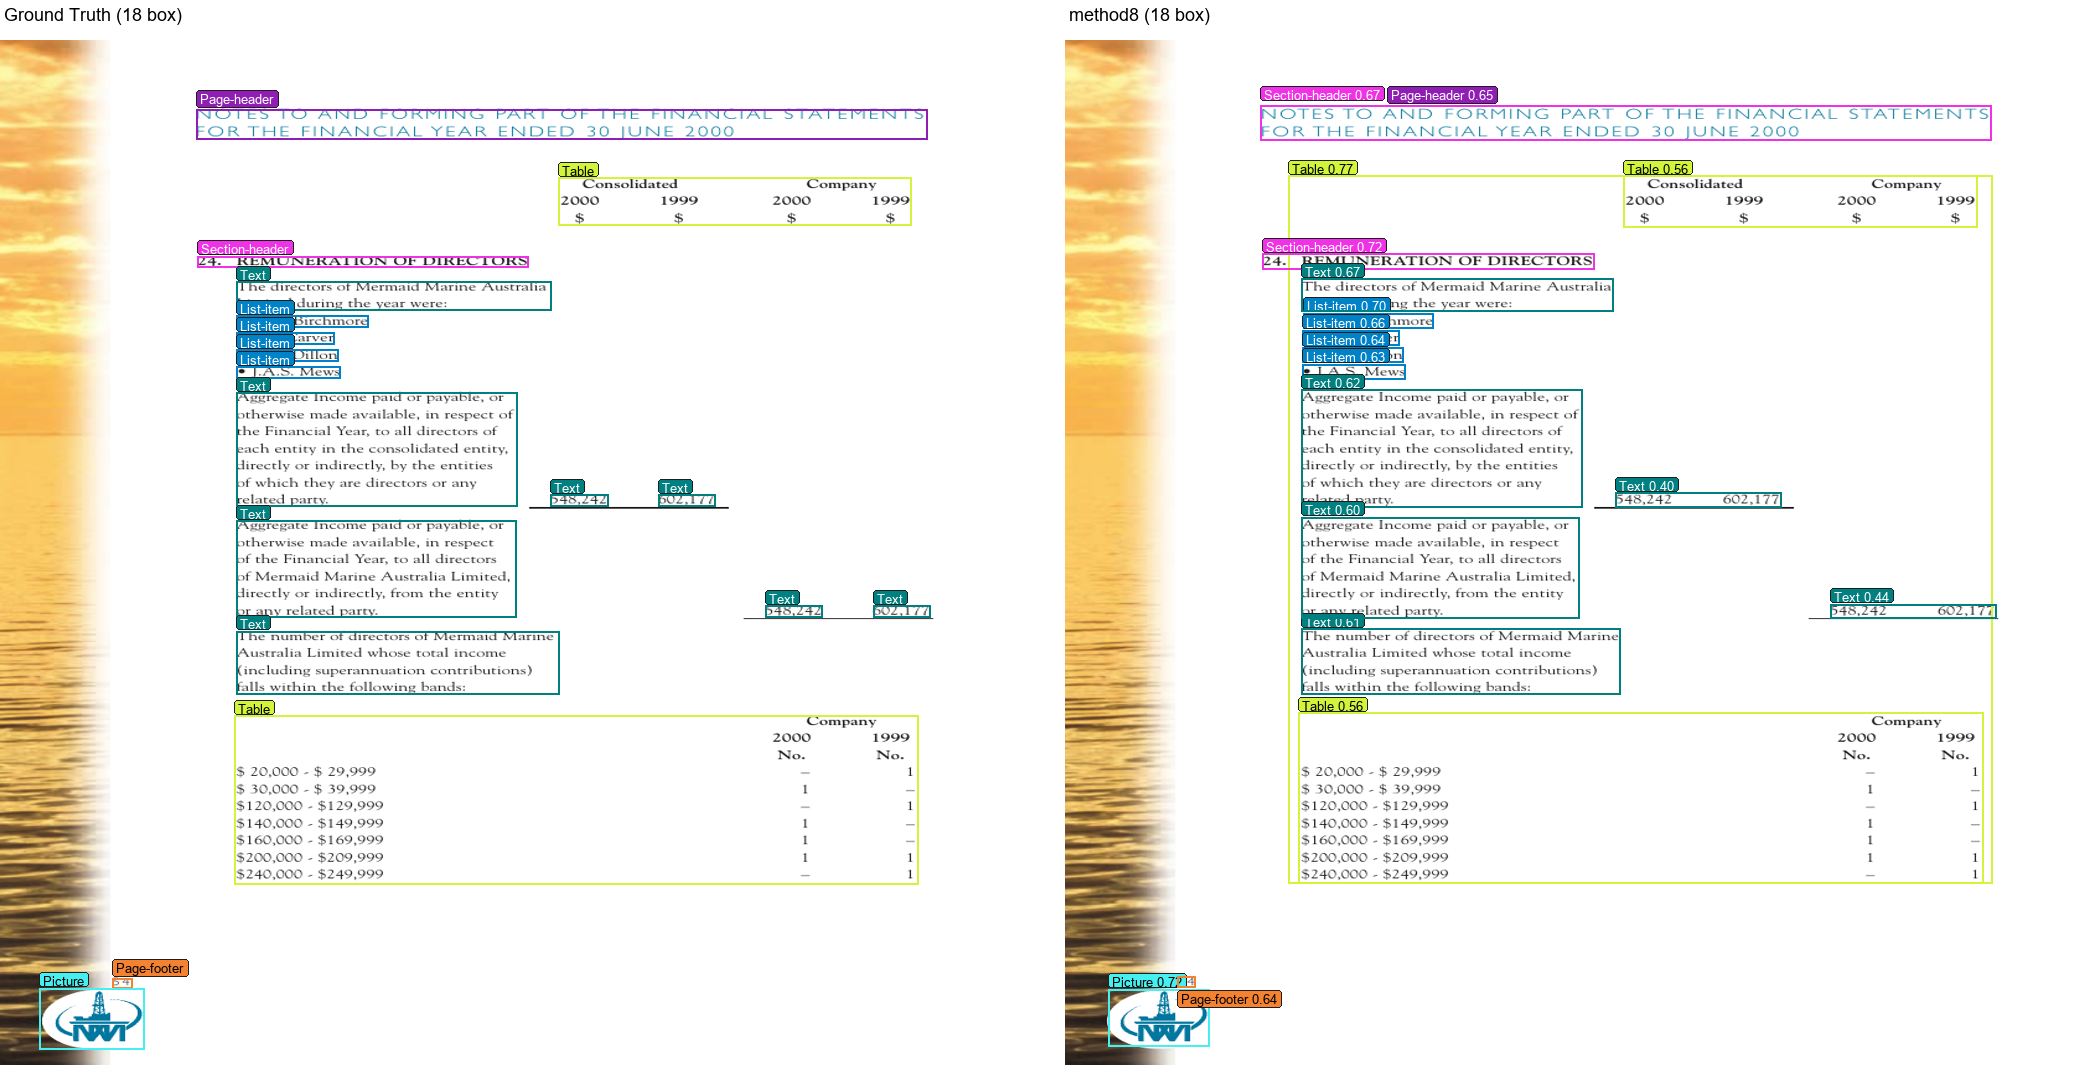

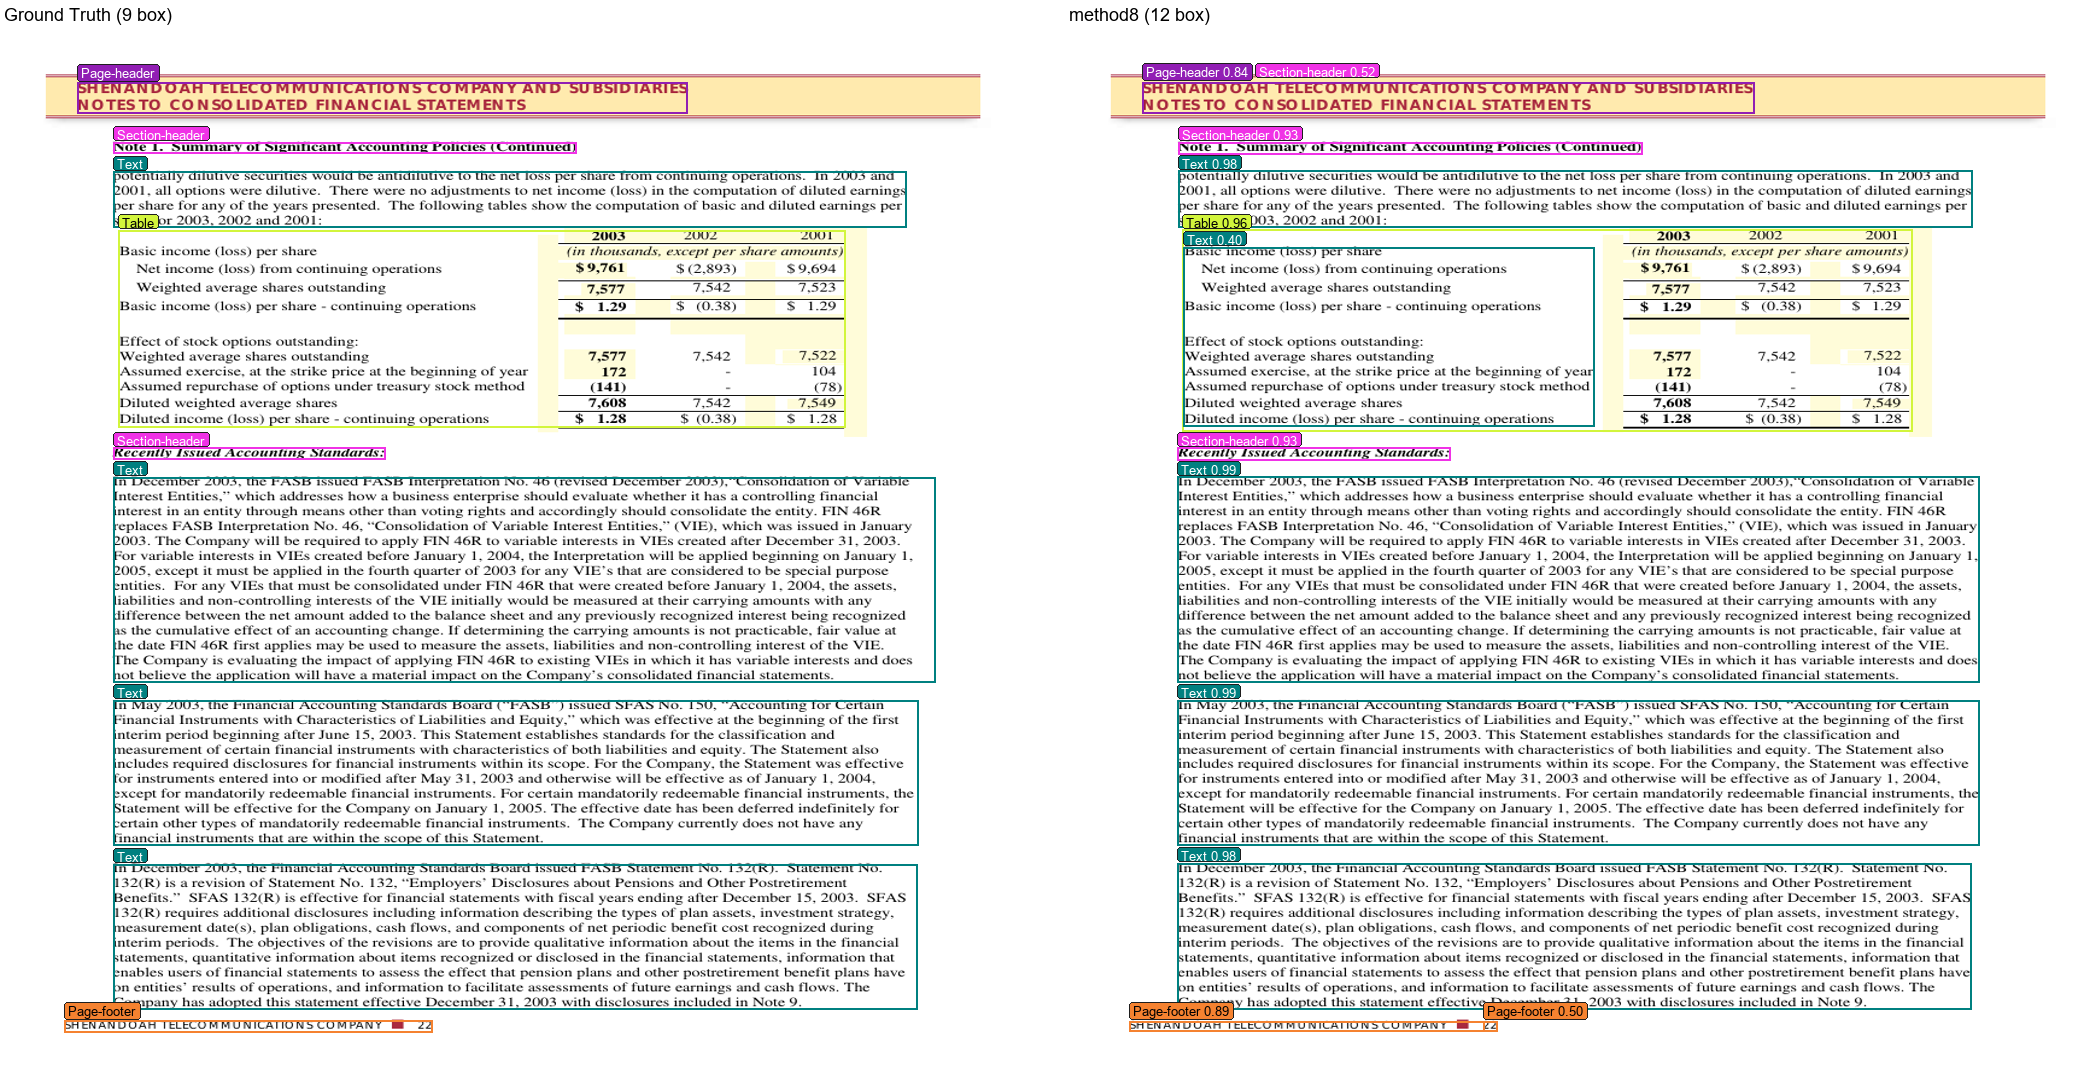

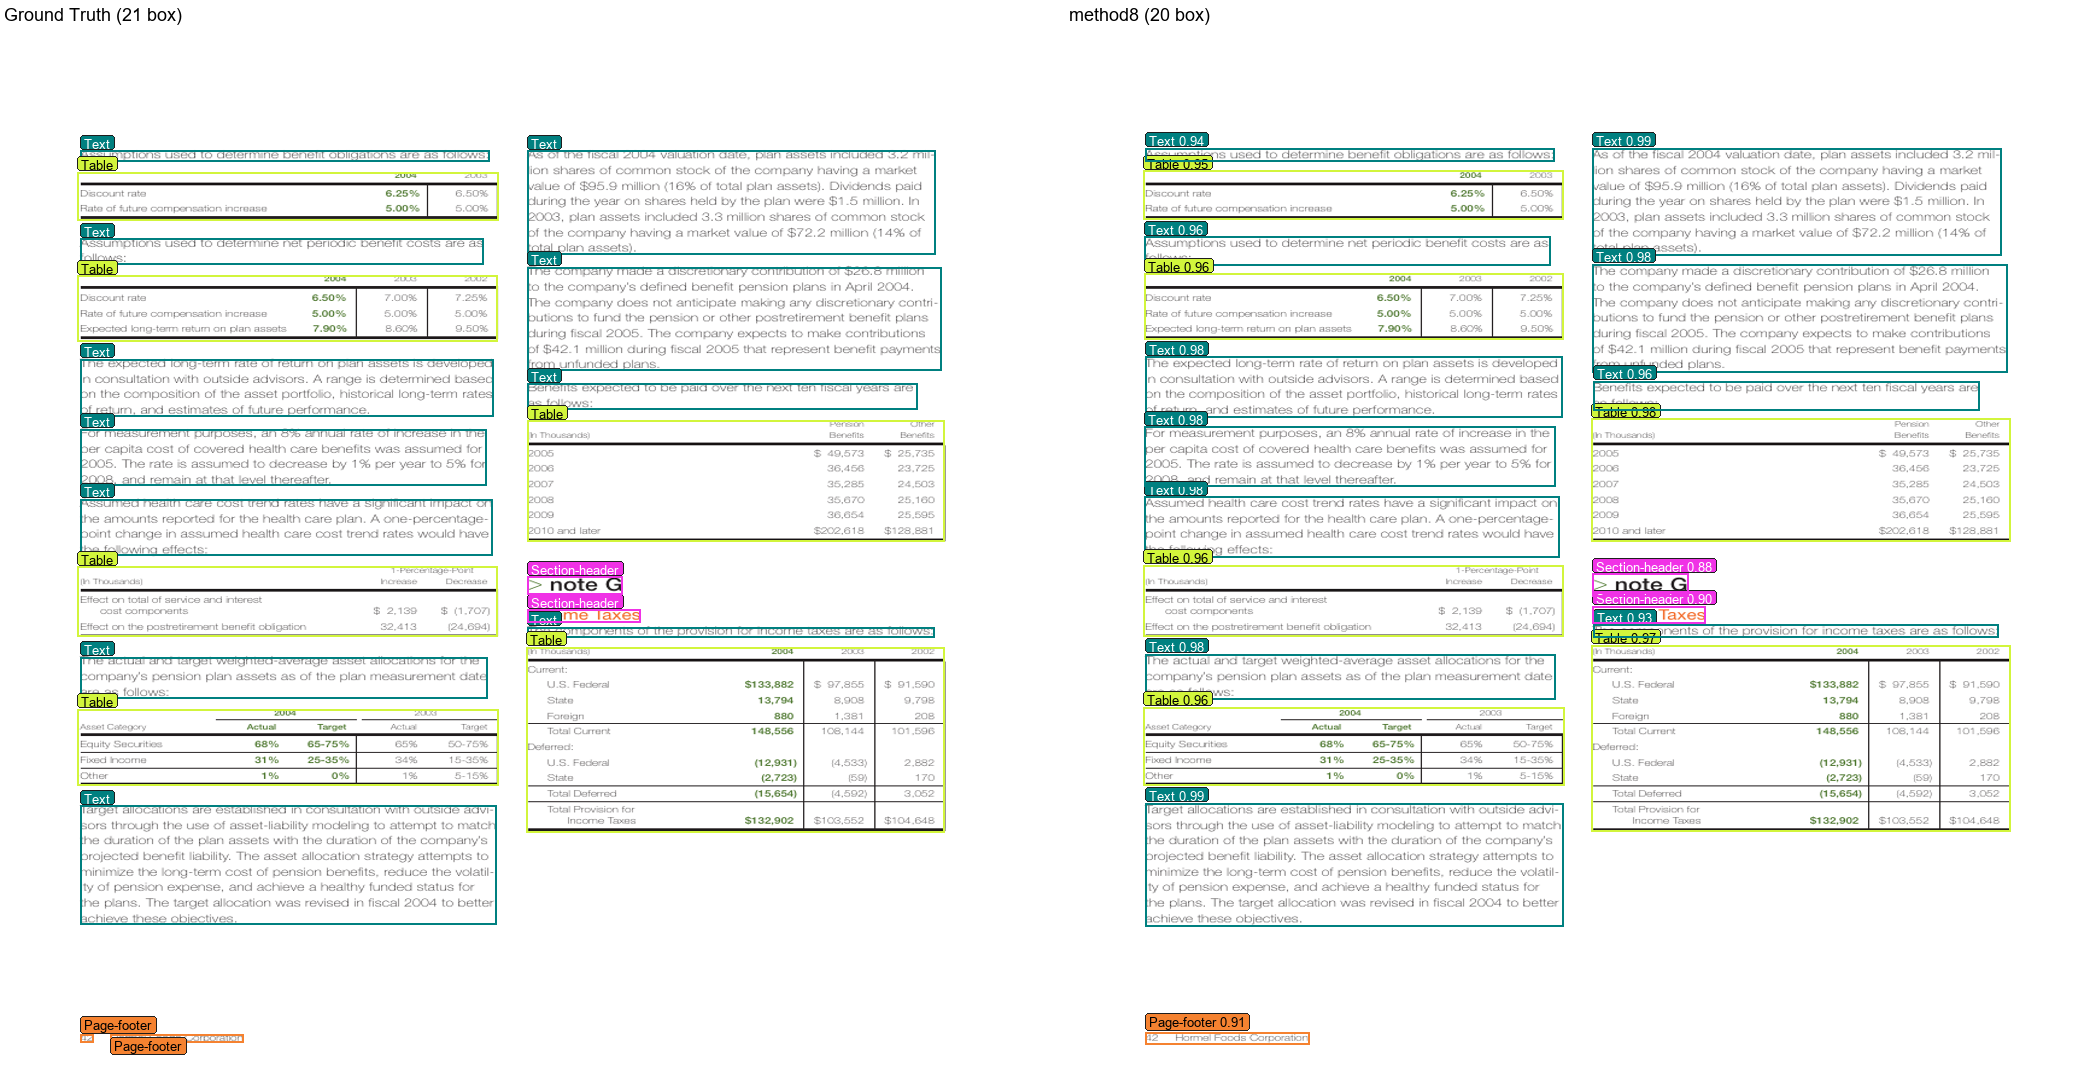

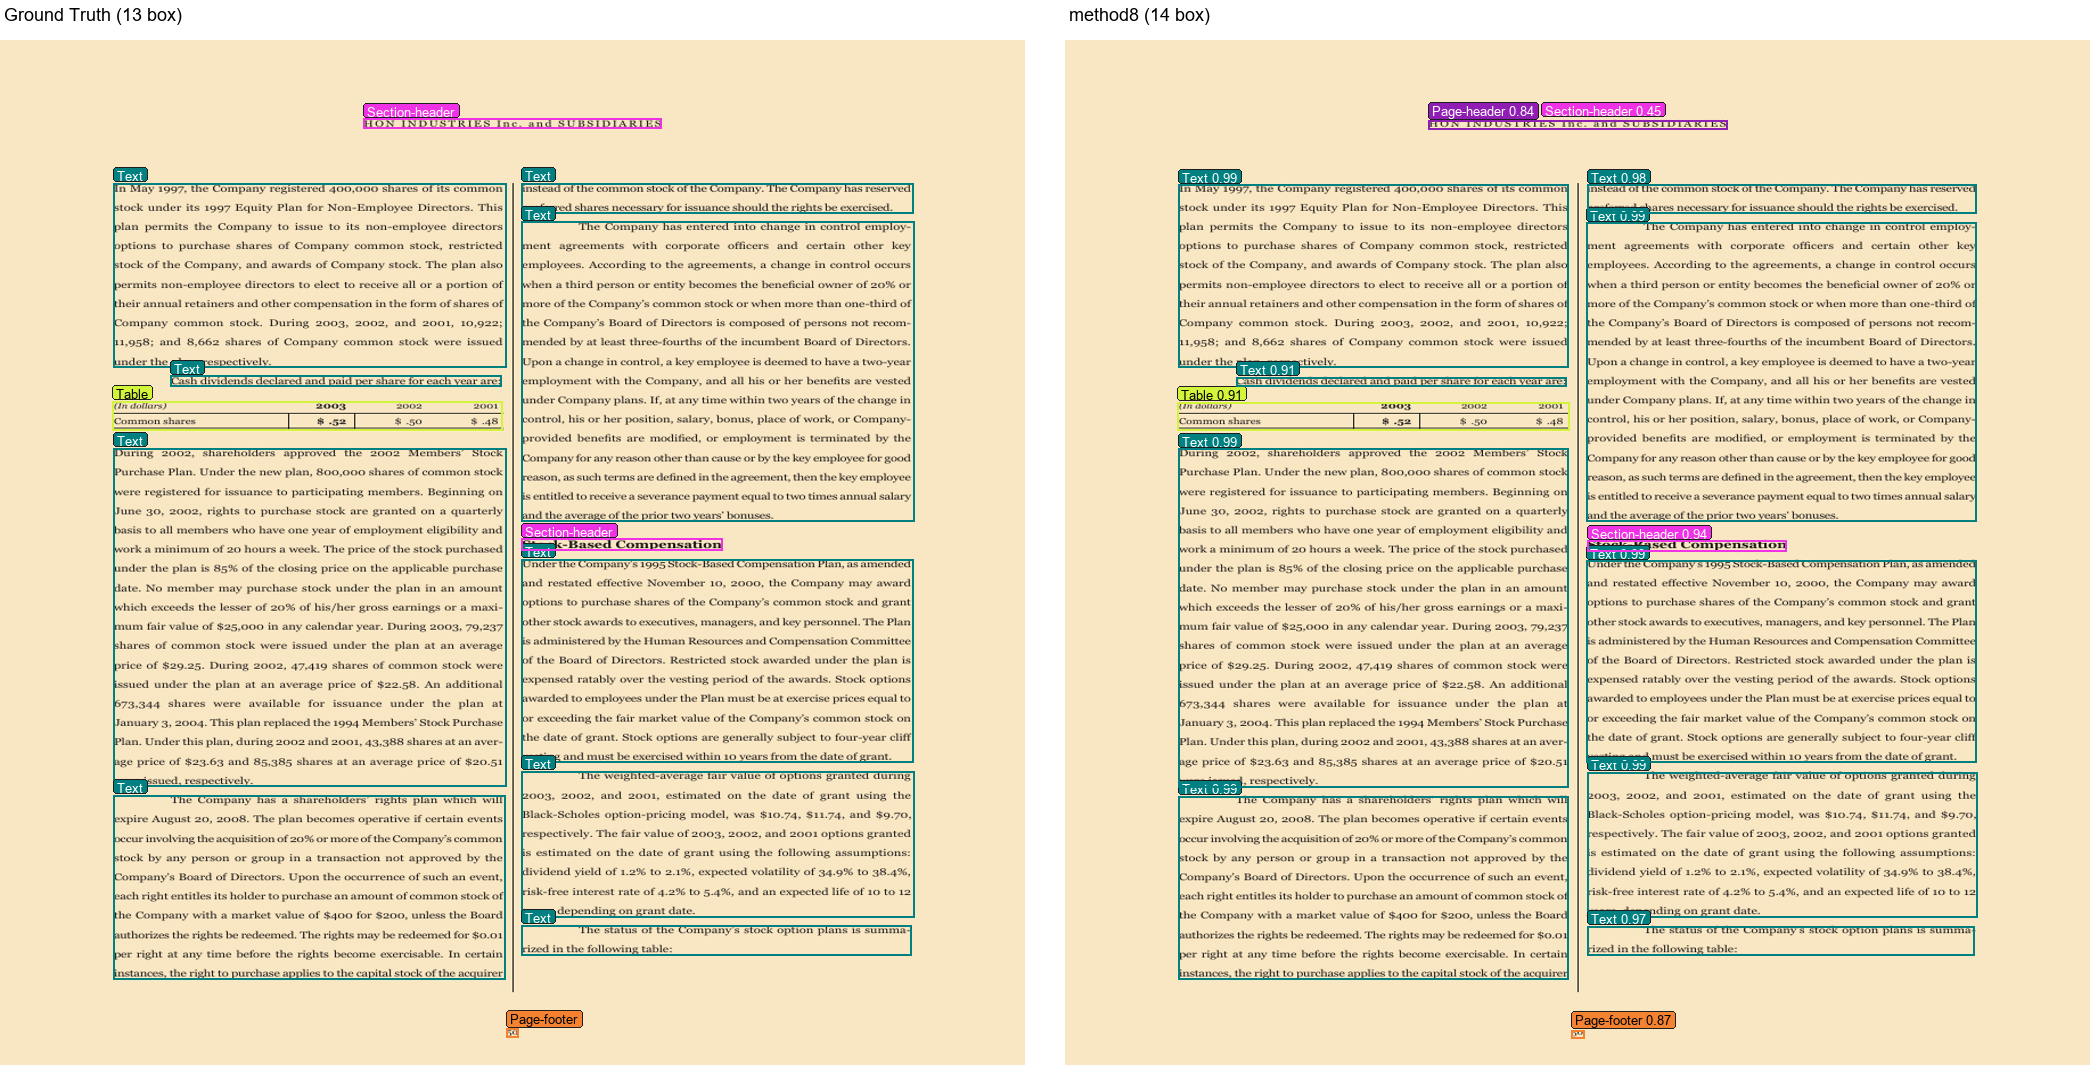

In [3]:
from IPython.display import Image as IPImage, display

vis_cmd = [
    sys.executable,
    str(ROOT / "visualization" / "scripts" / "visualize_predictions.py"),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", "10",
]
subprocess.run(vis_cmd, cwd=ROOT, check=True)

for idx in range(1, 11):
    fig_file = FIGURES_DIR / f"{idx}.png"
    if fig_file.exists():
        print(f"=== Sample Page {idx} ({fig_file.name}) ===")
        display(IPImage(filename=str(fig_file)))